# Hydroponics: cleaning and first look

A quick, reproducible analysis of `hydroponics_ml.csv`. The source CSV stays unchanged. The main analysis uses **one row per harvested tube**, with separate summaries for environmental observations. See [dataset_notes.md](dataset_notes.md) for how the workbook was combined.

Run all cells from top to bottom. Dependencies: `pandas`, `matplotlib`, and a Python Jupyter kernel. The last cell writes cleaned data and summary tables to `analysis_outputs/`.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})
candidates = [Path.cwd(), Path.cwd() / 'AI-Fellows-2027' / 'Matt']
DATA_DIR = next((p for p in candidates if (p / 'hydroponics_ml.csv').exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Open this notebook from its project folder or the AI Fellows repository root.')
raw = pd.read_csv(DATA_DIR / 'hydroponics_ml.csv', encoding='utf-8-sig', dtype='string')
print(f'Source: {len(raw):,} rows, {raw.shape[1]} columns')
display(raw['record_type'].value_counts().rename_axis('record_type').to_frame('rows'))


Source: 2,925 rows, 46 columns


,rows
record_type,
layout,2172
harvest,324
wall_lighting,252
seedling_lighting,72
water_output,54
lab_event,48
dissolved_oxygen,3


## 1. Clean types and inspect quality

Trim text, standardize blank cells, and explicitly convert dates and numeric columns. Keep physical identifiers as categories: zone 6 is a location, not six times zone 1. Preserve original zeros and missing values; do not impute values or automatically remove unusual observations.


In [2]:
clean = raw.copy()
clean.columns = clean.columns.str.strip().str.lower()
for col in clean.columns:
    clean[col] = clean[col].str.strip().replace('', pd.NA)

id_cols = ['wall_id', 'side', 'tube_id', 'slot_id', 'tray_id', 'light_zone', 'light_bar', 'position', 'trial']
date_cols = ['date', 'seed_date', 'transplant_date']
numeric_cols = ['plant_count', 'harvest_weight', 'fruit_count', 'leaves_slot_2',
    'leaves_slot_4', 'leaves_slot_6', 'mean_sampled_leaves', 'weight_per_plant',
    'days_since_sowing', 'days_since_transplant', 'light_value', 'light_zone_mean',
    'light_distance', 'water_volume_ml', 'water_duration_min', 'water_pressure_psi',
    'water_tube_trial_mean_ml', 'do_static', 'do_running', 'dap_reported']
conversion_issues = []
for col in date_cols + numeric_cols:
    old = clean[col]
    converted = (pd.to_datetime(old, format='%Y-%m-%d', errors='coerce') if col in date_cols
                 else pd.to_numeric(old, errors='coerce'))
    bad = old.notna() & converted.isna()
    if bad.any():
        conversion_issues.append({'column': col, 'invalid_values': int(bad.sum()),
                                  'examples': ', '.join(old[bad].unique()[:3])})
    clean[col] = converted
for col in id_cols + ['record_type', 'crop', 'variety', 'date_basis', 'harvest_weight_status']:
    clean[col] = clean[col].astype('category')

# Remove only exact duplicate rows; conflicting observations remain visible.
exact_duplicates = int(clean.duplicated().sum())
clean = clean.drop_duplicates().copy()
print(f'Exact duplicates removed: {exact_duplicates}')
print(f'Duplicate record IDs: {clean.record_id.duplicated().sum()}')
print(f'Conversion problems: {sum(x["invalid_values"] for x in conversion_issues)}')
if conversion_issues:
    display(pd.DataFrame(conversion_issues))
display(clean.dtypes.rename('dtype').to_frame())


Exact duplicates removed: 0
Duplicate record IDs: 0
Conversion problems: 0


,dtype
record_id,string
record_type,category
experiment_id,string
date,datetime64[us]
date_basis,category
crop,category
variety,category
variety_raw,string
wall_id,category
side,category


## 2. Harvest records and missingness

Most blanks in the combined CSV are structural: a lighting row has no harvest weight, for example. Evaluate missingness within the harvest subset rather than across unrelated record types. Fruit counts are relevant to cucumber and pepper; harvested plant counts and sampled leaves are recorded for leafy crops.


In [3]:
harvest = clean.loc[clean.record_type.eq('harvest')].copy()
key = ['experiment_id', 'crop', 'wall_id', 'side', 'tube_id', 'date']
conflicts = harvest.loc[harvest.duplicated(key, keep=False)].sort_values(key)
print(f'Harvest records: {len(harvest)}; duplicate harvest keys: {len(conflicts)}')
if len(conflicts):
    display(conflicts[key + ['record_id', 'harvest_weight']])

leaf_cols = ['leaves_slot_2', 'leaves_slot_4', 'leaves_slot_6']
# Recompute derived outcomes from observed measurements; zero counts remain zero.
harvest['mean_sampled_leaves'] = harvest[leaf_cols].mean(axis=1)
harvest['weight_per_plant'] = harvest.harvest_weight.div(harvest.plant_count.where(harvest.plant_count.gt(0)))
focus = ['harvest_weight', 'plant_count', 'fruit_count', *leaf_cols,
         'light_zone_mean', 'water_tube_trial_mean_ml', 'seed_date', 'transplant_date', 'date']
missingness = pd.DataFrame({'missing_n': harvest[focus].isna().sum(),
                           'missing_pct': harvest[focus].isna().mean().mul(100)})
display(missingness.sort_values('missing_pct', ascending=False))
display(pd.crosstab(harvest.crop, harvest.harvest_weight_status, dropna=False))
display(harvest.loc[harvest.harvest_weight.isna(),
    ['record_id', 'crop', 'wall_id', 'side', 'tube_id', 'harvest_weight_status']])


Harvest records: 324; duplicate harvest keys: 0


,missing_n,missing_pct
water_tube_trial_mean_ml,288,88.89
fruit_count,214,66.05
leaves_slot_2,114,35.19
leaves_slot_6,114,35.19
leaves_slot_4,114,35.19
plant_count,112,34.57
light_zone_mean,13,4.01
harvest_weight,4,1.23
seed_date,0,0.00
transplant_date,0,0.00


harvest_weight_status,lost data,not_recorded,observed
crop,,,
Arugula,2,0,26
Bell Pepper,0,2,54
Collards,0,0,56
Cucumber,0,0,56
Kale,0,0,28
Kale;Arugula,0,0,0
Lab,0,0,0
Lettuce,0,0,44
Spinach,0,0,56


,record_id,crop,wall_id,side,tube_id,harvest_weight_status
471,r00472,Arugula,2,A,37,lost data
473,r00474,Arugula,2,A,45,lost data
628,r00629,Bell Pepper,1,B,56,not_recorded
629,r00630,Bell Pepper,1,B,57,not_recorded


In [4]:
# Flag impossible values for review without silently deleting or fixing them.
checks = pd.Series({
    'negative_harvest_weight': int(harvest.harvest_weight.lt(0).sum()),
    'negative_fruit_count': int(harvest.fruit_count.lt(0).sum()),
    'nonpositive_recorded_plant_count': int(harvest.plant_count.le(0).sum()),
    'negative_sampled_leaf_counts': int(harvest[leaf_cols].lt(0).sum().sum()),
    'harvest_before_seed': int((harvest.date < harvest.seed_date).sum()),
    'harvest_before_transplant': int((harvest.date < harvest.transplant_date).sum()),
    'zero_weight_with_positive_fruit_count': int((harvest.harvest_weight.eq(0) & harvest.fruit_count.gt(0)).sum()),
}, name='flagged_n')
display(checks.to_frame())
print(f'Observed zero harvest weights: {harvest.harvest_weight.eq(0).sum()}')
display(harvest.date_basis.value_counts().to_frame('harvest_rows'))


,flagged_n
negative_harvest_weight,0
negative_fruit_count,0
nonpositive_recorded_plant_count,0
negative_sampled_leaf_counts,0
harvest_before_seed,0
harvest_before_transplant,0
zero_weight_with_positive_fruit_count,0


Observed zero harvest weights: 7


,harvest_rows
date_basis,
inferred_crop_wall_harvest_log,324
explicit_log_date,0
explicit_measurement_date,0


## 3. Summary statistics

Summarize within crops and varieties because the harvest measurements represent different products. Leafy weights appear to be grams from workbook summaries; fruit-weight units need confirmation. `weight_per_plant` is tube weight divided by recorded harvested plant count, not fruit count. Harvest dates were inferred from crop logs.


In [5]:
crop_summary = harvest.groupby('crop', observed=True).agg(
    tube_records=('record_id', 'size'), weight_observed=('harvest_weight', 'count'),
    mean_weight=('harvest_weight', 'mean'), median_weight=('harvest_weight', 'median'),
    sd_weight=('harvest_weight', 'std'), min_weight=('harvest_weight', 'min'),
    max_weight=('harvest_weight', 'max'), mean_weight_per_plant=('weight_per_plant', 'mean'),
    mean_fruit_count=('fruit_count', 'mean'), mean_sampled_leaves=('mean_sampled_leaves', 'mean'),
    mean_light=('light_zone_mean', 'mean'))
variety_summary = harvest.groupby(['crop', 'variety'], observed=True).agg(
    tube_records=('record_id', 'size'), weight_observed=('harvest_weight', 'count'),
    mean_weight=('harvest_weight', 'mean'), median_weight=('harvest_weight', 'median'),
    sd_weight=('harvest_weight', 'std'), mean_weight_per_plant=('weight_per_plant', 'mean'))
wall_summary = harvest.groupby(['crop', 'wall_id', 'side'], observed=True).agg(
    tube_records=('record_id', 'size'), weight_observed=('harvest_weight', 'count'),
    mean_weight=('harvest_weight', 'mean'), mean_light=('light_zone_mean', 'mean'))
display(crop_summary)
display(variety_summary)
display(wall_summary)


,tube_records,weight_observed,mean_weight,median_weight,sd_weight,min_weight,max_weight,mean_weight_per_plant,mean_fruit_count,mean_sampled_leaves,mean_light
crop,,,,,,,,,,,
Arugula,28,26,276.95,268.81,57.75,153.70,378.00,46.60,<NA>,28.24,142.94
Bell Pepper,56,54,62.59,40.50,58.37,0.00,321.00,<NA>,14.52,<NA>,129.16
Collards,56,56,249.74,247.74,50.53,163.03,387.00,41.87,<NA>,18.60,145.31
Cucumber,56,56,125.55,104.00,98.99,0.00,427.00,<NA>,2.54,<NA>,126.46
Kale,28,28,178.83,178.78,38.36,99.02,253.60,35.77,<NA>,12.40,144.32
Lettuce,44,44,212.60,210.82,94.22,40.76,379.03,38.29,<NA>,27.15,138.61
Spinach,56,56,67.53,66.40,13.04,43.69,101.27,11.67,<NA>,21.62,144.38


tube_records  weight_observed  mean_weight  \
crop        variety                                                    
Arugula     Arugula                 28               26       276.95   
Bell Pepper Islander                28               26        79.35   
            Lunchbox                28               28        47.04   
Collards    Flash                   28               28       268.81   
            Top Bunch               28               28       230.66   
Cucumber    Katrina                 28               28       103.96   
            Unagi                   28               28       147.14   
Kale        Kale                    28               28       178.83   
Lettuce     Green Butter            20               20       141.68   
            Tropicana               24               24       271.71   
Spinach     Bloomsdale              28               28        66.93   
            Space                   28               28        68.13   

                          median_weight  sd_weight  mean_weight_per_plant  
crop        variety                                                        
Arugula     Arugula              268.81      57.75                  46.60  
Bell Pepper Islander              56.50      73.05                   <NA>  
            Lunchbox              37.00      35.01                   <NA>  
Collards    Flash                275.04      53.51                  45.00  
            Top Bunch            234.41      39.78                  38.74  
Cucumber    Katrina               89.50      84.58                   <NA>  
            Unagi                133.00     108.81                   <NA>  
Kale        Kale                 178.78      38.36                  35.77  
Lettuce     Green Butter         137.27      56.87                  27.40  
            Tropicana            290.53      76.84                  47.36  
Spinach     Bloomsdale            66.10      13.31                  11.48  
            Space                 68.28      12.98                  11.85

tube_records  weight_observed  mean_weight  \
crop        wall_id side                                               
Arugula     2       A                7                5       259.51   
                    B                7                7       281.38   
            3       A                7                7       256.11   
                    B                7                7       305.80   
Bell Pepper 1       A               28               28        65.21   
                    B               28               26        59.77   
Collards    2       A               14               14       256.68   
                    B               14               14       239.39   
            3       A               14               14       250.56   
                    B               14               14       252.32   
Cucumber    1       A               28               28       125.89   
                    B               28               28       125.21   
Kale        2       A                7                7       171.83   
                    B                7                7       180.15   
            3       A                7                7       171.16   
                    B                7                7       192.20   
Lettuce     2       A               11               11       200.30   
                    B               11               11       214.68   
            3       A               11               11       222.00   
                    B               11               11       213.44   
Spinach     2       A               14               14        73.68   
                    B               14               14        66.12   
            3       A               14               14        69.07   
                    B               14               14        61.25   

                          mean_light  
crop        wall_id side              
Arugula     2       A         125.45  
                    B         128.29  
            3       A         134.45  
                    B         182.36  
Bell Pepper 1       A         132.05  
                    B         126.27  
Collards    2       A         125.98  
                    B         130.10  
            3       A         134.45  
                    B         189.16  
Cucumber    1       A         127.44  
                    B         125.36  
Kale        2       A         128.31  
                    B         130.47  
            3       A         134.45  
                    B         182.65  
Lettuce     2       A         120.86  
                    B         126.74  
            3       A         131.25  
                    B         179.31  
Spinach     2       A         125.95  
                    B         128.71  
            3       A         137.17  
                    B         185.17

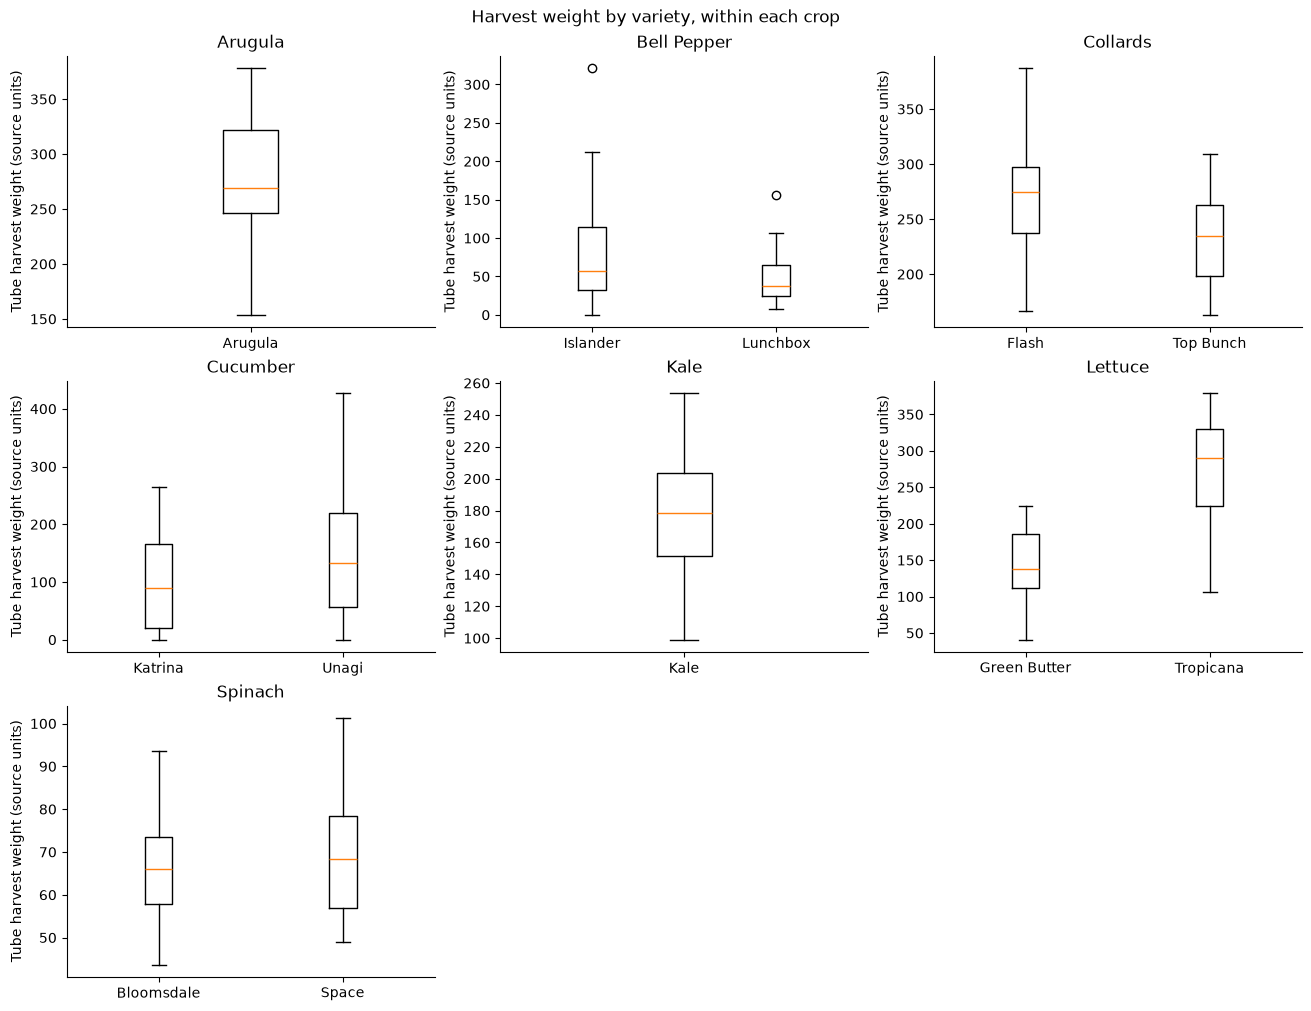

In [6]:
crops = sorted(harvest.crop.dropna().unique())
fig, axes = plt.subplots(3, 3, figsize=(13, 10), constrained_layout=True)
for ax, crop in zip(axes.flat, crops):
    sub = harvest.loc[harvest.crop.eq(crop)]
    groups = [(str(v), g.harvest_weight.dropna().to_numpy(dtype=float))
              for v, g in sub.groupby('variety', observed=True)]
    ax.boxplot([values for _, values in groups], tick_labels=[v for v, _ in groups])
    ax.set(title=str(crop), ylabel='Tube harvest weight (source units)')
for ax in list(axes.flat)[len(crops):]:
    ax.set_visible(False)
fig.suptitle('Harvest weight by variety, within each crop')
plt.show()


## 4. Environmental observations

These summaries use the original environmental record types so readings repeated as harvest context are not counted as independent measurements. Lighting and dissolved-oxygen units were not specified; water output is mL per five-minute trial at 25 psi. Grow-wall oxygen readings do not identify a numbered wall.


In [7]:
lighting = clean.loc[clean.record_type.eq('wall_lighting')]
light_summary = lighting.groupby(['wall_id', 'side', 'light_zone'], observed=True).agg(
    readings=('light_value', 'count'), mean_light=('light_value', 'mean'),
    sd_light=('light_value', 'std'), min_light=('light_value', 'min'), max_light=('light_value', 'max'))
water = clean.loc[clean.record_type.eq('water_output')]
water_summary = water.groupby(['wall_id', 'tube_id'], observed=True).water_volume_ml.agg(['count', 'mean', 'std', 'min', 'max'])
seedling = clean.loc[clean.record_type.eq('seedling_lighting')]
seedling_summary = seedling.groupby('position', observed=True).light_value.agg(['count', 'mean', 'std', 'min', 'max'])
display(light_summary)
display(water_summary)
display(seedling_summary)
display(clean.loc[clean.record_type.eq('dissolved_oxygen'), ['date', 'tank', 'do_static', 'do_running']])


readings  mean_light  sd_light  min_light  max_light
wall_id side light_zone                                                      
1       A    1                  7      167.70     14.32     140.08     182.00
             2                  7      127.86     14.72     110.90     146.70
             3                  7      101.76     17.14      73.10     118.90
             4                  7      106.34     15.66      81.70     125.50
             5                  7      122.27     18.09      92.50     142.10
             6                  7      163.26     20.54     120.00     177.90
        B    1                  7      166.00     13.82     149.40     193.90
             2                  7      113.47      5.63     104.40     122.40
             3                  7      103.63      8.33      95.60     121.40
             4                  7      100.00      7.08      92.50     114.30
             5                  7      101.49      6.60      90.90     111.20
             6                  7      157.44     10.64     136.90     166.30
2       A    1                  7      172.70     17.10     141.90     193.00
             2                  7      127.39     10.66     107.70     141.40
             3                  7      107.37      4.88      99.00     111.60
             4                  7       94.40      5.26      87.00     100.40
             5                  7      114.79      4.95     107.50     120.20
             6                  7      154.13      9.00     136.40     160.90
        B    1                  7      161.63      8.18     145.90     169.70
             2                  7      125.17      6.06     117.00     134.40
             3                  7      109.91      4.53     102.60     117.80
             4                  7      100.47      6.49      87.00     107.50
             5                  7      135.21      6.63     130.10     149.10
             6                  7      155.71      9.21     136.10     163.20
3       A    1                  7      169.76      7.97     159.50     184.90
             2                  7      123.50      6.31     113.90     131.70
             3                  7      111.41     11.11     100.20     132.70
             4                  7      106.36      6.27      93.90     111.40
             5                  7      132.10      7.45     120.20     140.40
             6                  7      163.60     13.66     136.50     176.20
        B    1                  7      233.44     29.17     211.60     297.00
             2                  7      178.00     12.80     160.20     191.60
             3                  7      148.56      5.42     139.80     154.90
             4                  7      146.51      7.29     136.60     155.40
             5                  7      183.80     11.64     167.70     198.20
             6                  7      239.67     22.14     214.00     280.70

count   mean    std  min  max
wall_id tube_id                               
1       19           4 317.50  89.21  260  450
        26           4 317.50  89.21  260  450
        3            4 306.25  90.13  250  440
        32           4 321.25  76.42  270  435
        39           4 323.75  81.38  270  445
        55           4 341.25  79.41  295  460
2       19           3 360.00  95.39  300  470
        26           3 403.33  92.38  350  510
        3            3 320.00  86.60  270  420
        32           3 383.33  83.86  330  480
        39           3 370.00  78.10  320  460
        55           3 373.33  85.05  310  470
3       19           2 345.00  91.92  280  410
        26           2 370.00  56.57  330  410
        3            2 300.00 127.28  210  390
        32           2 375.00  91.92  310  440
        39           2 365.00  77.78  310  420
        55           2 360.00  84.85  300  420

,count,mean,std,min,max
position,,,,,
back,24,216.38,56.65,133.90,338.60
front,24,108.46,15.59,80.90,148.60
middle,24,145.47,24.30,79.90,186.50


,date,tank,do_static,do_running
750,2026-03-27,Seedling,9.36,8.94
751,2026-03-27,Grow Wall,8.75,8.65
752,2026-03-30,Grow Wall,8.40,8.46


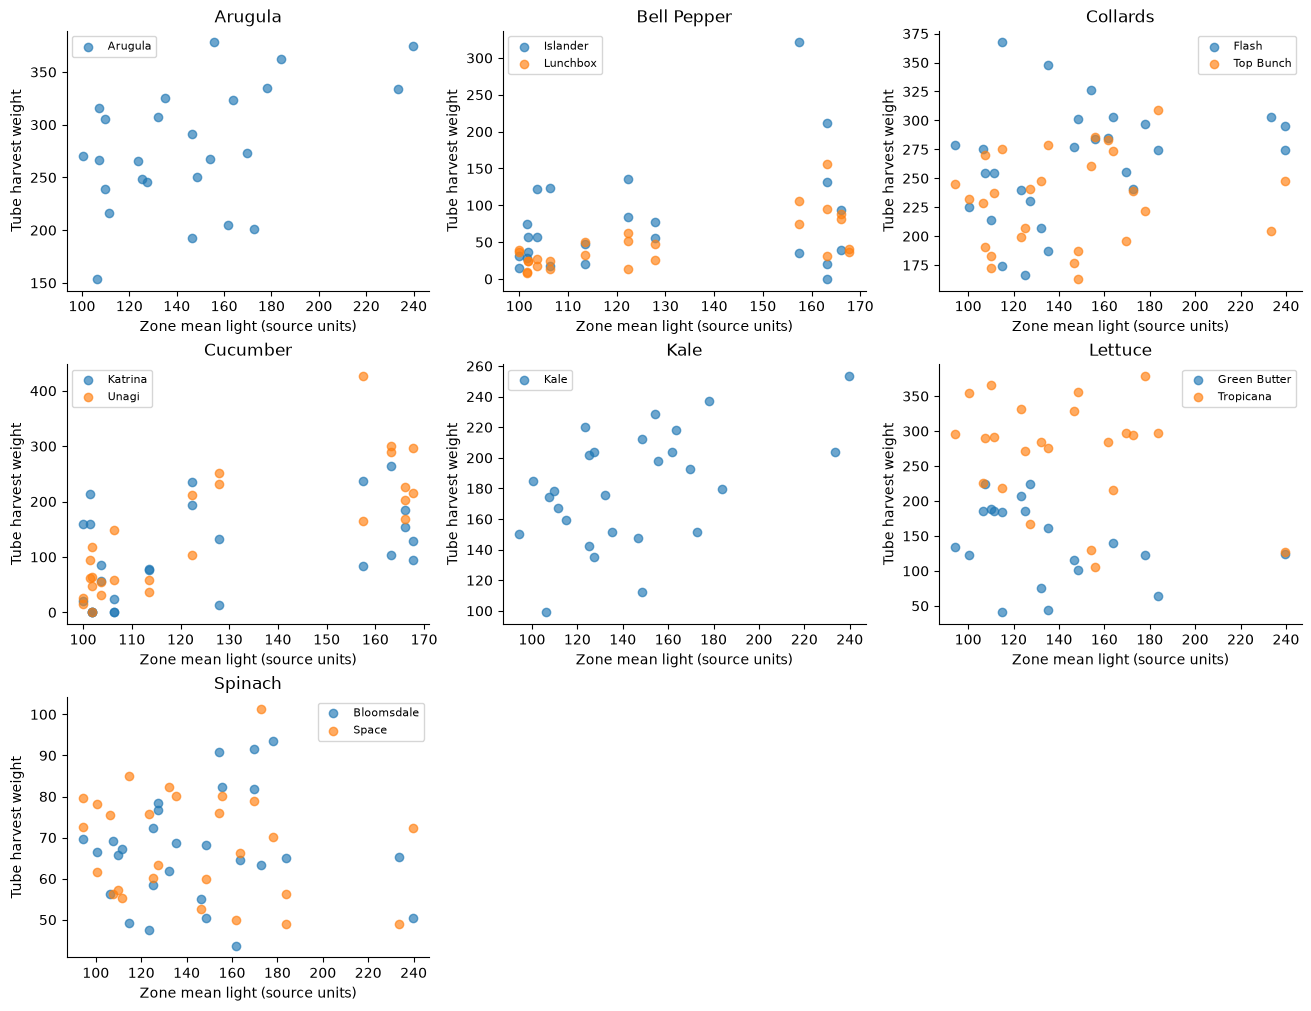

In [8]:
# Descriptive only: a zone's light mean is shared by several tubes.
fig, axes = plt.subplots(3, 3, figsize=(13, 10), constrained_layout=True)
for ax, crop in zip(axes.flat, crops):
    sub = harvest.loc[harvest.crop.eq(crop)].dropna(subset=['light_zone_mean', 'harvest_weight'])
    for variety, group in sub.groupby('variety', observed=True):
        ax.scatter(group.light_zone_mean, group.harvest_weight, alpha=0.65, label=str(variety))
    ax.set(title=str(crop), xlabel='Zone mean light (source units)', ylabel='Tube harvest weight')
    ax.legend(fontsize=8)
for ax in list(axes.flat)[len(crops):]:
    ax.set_visible(False)
plt.show()


## Interpretation and next steps

- Missing harvest weights stay missing; explicitly recorded zeros stay zero. Use the counts above when interpreting means.
- Differences between varieties, walls, and lighting zones are descriptive. Plants share wall conditions, zone readings are repeated across tubes, and crops are unevenly distributed across walls. These plots do not establish a lighting effect.
- Retain the provenance and inferred-date labels. Confirm weight/light units and crop harvest dates before formal modeling.
- For future weather and nutrient records, summarize exposures over the growth period and join by experiment, date range, and wall/tank where available.
- For prediction of harvest weight, exclude `weight_per_plant`, other harvest-derived outcomes, and post-harvest notes from predictors. Use experimental groups when splitting training and test data.


In [9]:
OUT = DATA_DIR / 'analysis_outputs'
OUT.mkdir(exist_ok=True)
clean.to_csv(OUT / 'hydroponics_cleaned.csv', index=False, date_format='%Y-%m-%d')
harvest.to_csv(OUT / 'harvest_cleaned.csv', index=False, date_format='%Y-%m-%d')
for name, table in {'harvest_missingness': missingness, 'crop_summary': crop_summary,
                    'variety_summary': variety_summary, 'wall_summary': wall_summary,
                    'lighting_summary': light_summary, 'water_summary': water_summary,
                    'seedling_light_summary': seedling_summary}.items():
    table.to_csv(OUT / f'{name}.csv')
print(f'Saved cleaned data and summaries to {OUT}')


Saved cleaned data and summaries to C:\Users\tbelcher\AI Fellows\AI-Fellows-2027\Matt\analysis_outputs
